In [9]:
%pip install xgboost seaborn scikit-learn shap openpyxl

Note: you may need to restart the kernel to use updated packages.


In [ ]:
## 1. Setup and data
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import shap
from matplotlib.patches import Patch
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, roc_curve
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
np.random.seed(42)

STAY = "#2a78d6"
CHURN = "#eb6834"
GREY = "#8a8984"
plt.rcParams["font.size"] = 11
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e6e5e0"
plt.rcParams["axes.axisbelow"] = True

data_dir = Path("telecom")  # folder with Client.csv and Record.csv
out_dir = data_dir / "results"
(out_dir / "figures").mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(out_dir / "figures" / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white")

client = pd.read_csv(data_dir / "Client.csv")
record = pd.read_csv(data_dir / "Record.csv")
df = record.merge(client, on="Customer_ID", how="inner", validate="one_to_one")
print("Client:", client.shape, "| Record:", record.shape, "| Merged:", df.shape)
df.head()

Client: (100000, 50) | Record: (100000, 51) | Merged: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


77 numeric columns, 21 categorical columns
43 columns have missing values
Negative equipment age: 133


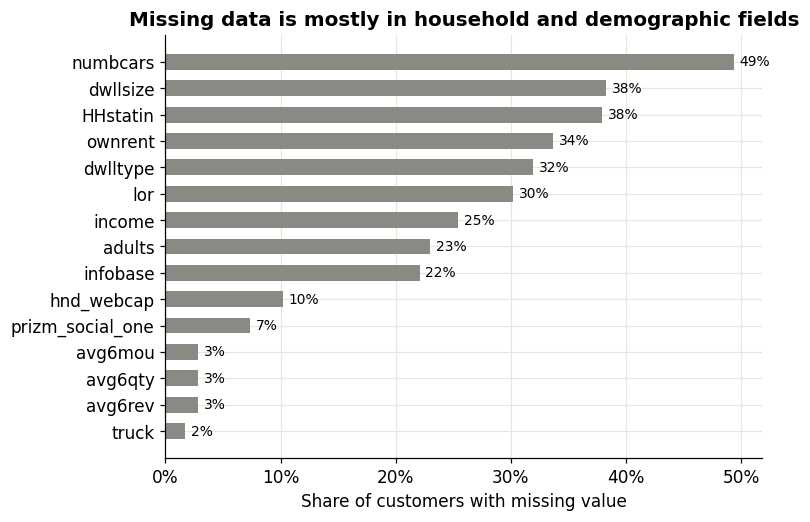


Churn rate: 49.6%
Monthly revenue of churners: $2,870,796 (49.1% of total)
Per year: $34,449,546


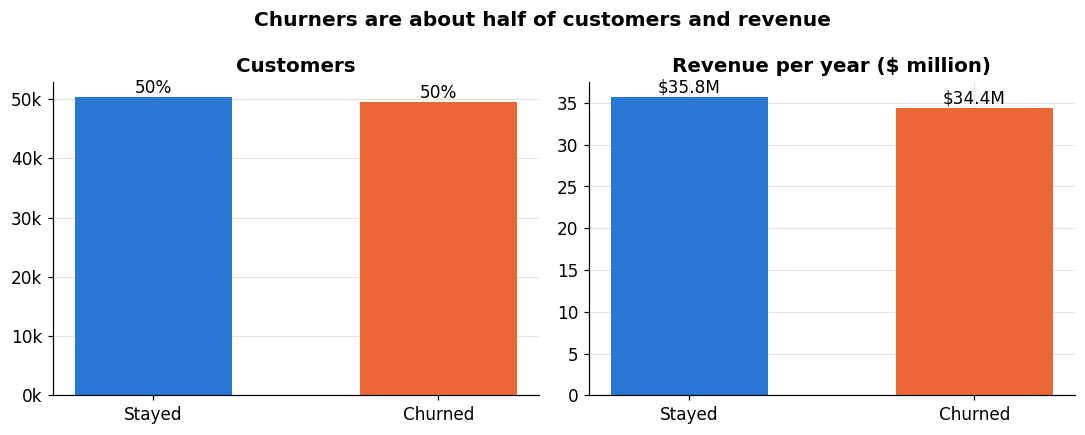

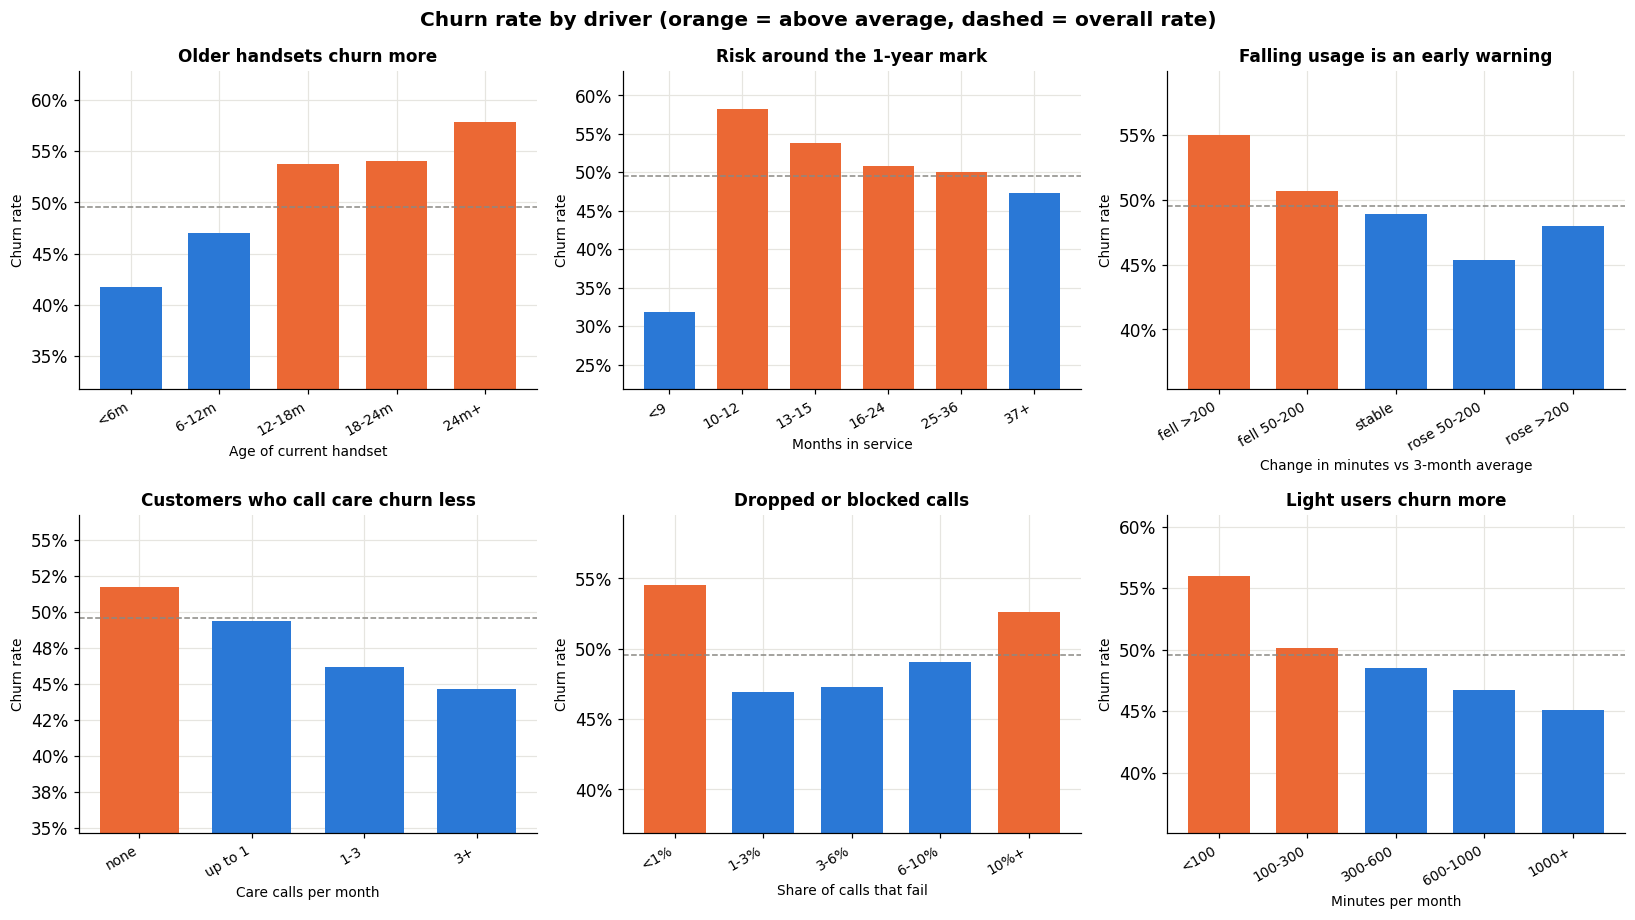

Handset age    <6m: 41.7% | 6-12m: 47.0% | 12-18m: 53.7% | 18-24m: 54.0% | 24m+: 57.9%
Tenure         <9: 31.8% | 10-12: 58.2% | 13-15: 53.8% | 16-24: 50.8% | 25-36: 50.0% | 37+: 47.3%
Usage change   fell >200: 55.0% | fell 50-200: 50.7% | stable: 48.9% | rose 50-200: 45.4% | rose >200: 48.0%
Customer care  none: 51.8% | up to 1: 49.4% | 1-3: 46.2% | 3+: 44.7%
Call failure   <1%: 54.5% | 1-3%: 46.9% | 3-6%: 47.3% | 6-10%: 49.1% | 10%+: 52.7%
Monthly usage  <100: 56.0% | 100-300: 50.2% | 300-600: 48.5% | 600-1000: 46.7% | 1000+: 45.1%


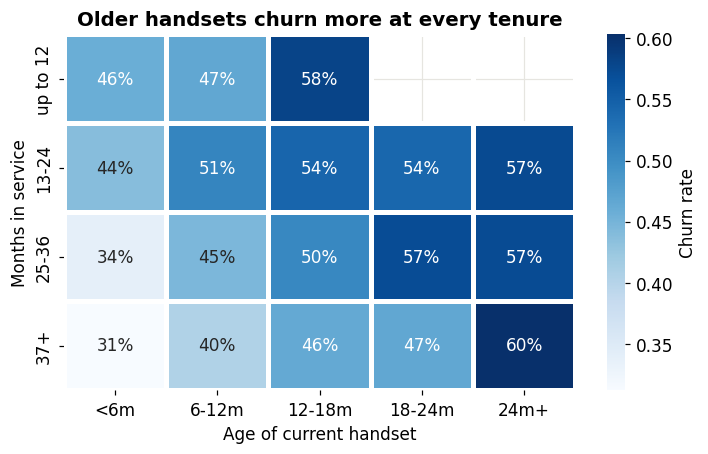

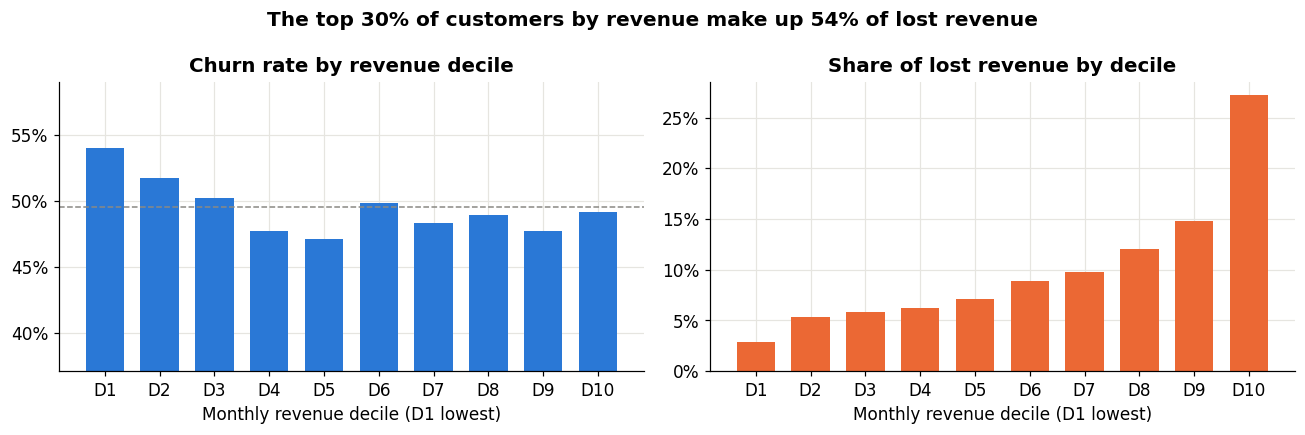

            churn_rate      revenue  lost_share
rev_decile                                     
D1               0.541   151377.686       0.029
D2               0.517   294674.631       0.053
D3               0.503   331434.563       0.058
D4               0.477   371620.135       0.062
D5               0.471   436170.437       0.072
D6               0.498   509802.180       0.089
D7               0.483   582390.414       0.098
D8               0.490   705896.702       0.120
D9               0.478   892568.453       0.148
D10              0.492  1575100.248       0.272

Column pairs with correlation above 0.95: 19


In [ ]:
## 2. Exploratory data analysis
# data quality
cat_cols_raw = df.select_dtypes(exclude="number").columns.tolist()
num_cols_raw = df.select_dtypes(include="number").columns.drop(["churn", "Customer_ID"]).tolist()
print(len(num_cols_raw), "numeric columns,", len(cat_cols_raw), "categorical columns")
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print(len(miss), "columns have missing values")
print("Negative equipment age:", (df["eqpdays"] < 0).sum())

top = miss.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values * 100, color=GREY, height=0.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Share of customers with missing value")
ax.set_title("Missing data is mostly in household and demographic fields", fontweight="bold")
for y, v in enumerate(top.values):
    ax.text(v * 100 + 0.5, y, f"{v:.0%}", va="center", fontsize=9)
save(fig, "01_missing")
plt.show()

# churn and revenue
churn_rate = df["churn"].mean()
n_customers = len(df)
rev_total = df["rev_Mean"].sum()
rev_churners = df.loc[df["churn"] == 1, "rev_Mean"].sum()
print(f"\nChurn rate: {churn_rate:.1%}")
print(f"Monthly revenue of churners: ${rev_churners:,.0f} ({rev_churners / rev_total:.1%} of total)")
print(f"Per year: ${rev_churners * 12:,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
counts = df["churn"].value_counts().sort_index()
axes[0].bar(["Stayed", "Churned"], counts.values, color=[STAY, CHURN], width=0.55)
axes[0].set_title("Customers")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v / n_customers:.0%}", ha="center", va="bottom")
rev = df.groupby("churn")["rev_Mean"].sum() * 12 / 1e6
axes[1].bar(["Stayed", "Churned"], rev.values, color=[STAY, CHURN], width=0.55)
axes[1].set_title("Revenue per year ($ million)")
for i, v in enumerate(rev.values):
    axes[1].text(i, v, f"${v:.1f}M", ha="center", va="bottom")
fig.suptitle("Churners are about half of customers and revenue", fontweight="bold")
fig.tight_layout()
save(fig, "02_churn_size")
plt.show()

# churn rate by driver
def churn_by_bins(col, bins, labels, ax, title, xlabel):
    s = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
    g = df.groupby(s, observed=False)["churn"].mean()
    ax.bar(range(len(g)), g * 100, color=[CHURN if m > churn_rate else STAY for m in g], width=0.7)
    ax.axhline(churn_rate * 100, ls="--", color=GREY, lw=1)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels(g.index, rotation=30, ha="right", fontsize=9)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_ylim(max(0, g.min() * 100 - 10), g.max() * 100 + 5)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel("Churn rate", fontsize=9)
    return g

df["fail_rate"] = df["drop_blk_Mean"] / (df["attempt_Mean"] + 1)
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
drivers = {
    "Handset age": churn_by_bins("eqpdays", [-np.inf, 180, 365, 540, 730, np.inf],
        ["<6m", "6-12m", "12-18m", "18-24m", "24m+"], axes[0, 0], "Older handsets churn more", "Age of current handset"),
    "Tenure": churn_by_bins("months", [0, 9, 12, 15, 24, 36, np.inf],
        ["<9", "10-12", "13-15", "16-24", "25-36", "37+"], axes[0, 1], "Risk around the 1-year mark", "Months in service"),
    "Usage change": churn_by_bins("change_mou", [-np.inf, -200, -50, 50, 200, np.inf],
        ["fell >200", "fell 50-200", "stable", "rose 50-200", "rose >200"], axes[0, 2],
        "Falling usage is an early warning", "Change in minutes vs 3-month average"),
    "Customer care": churn_by_bins("custcare_Mean", [-np.inf, 0, 1, 3, np.inf],
        ["none", "up to 1", "1-3", "3+"], axes[1, 0], "Customers who call care churn less", "Care calls per month"),
    "Call failure": churn_by_bins("fail_rate", [-np.inf, 0.01, 0.03, 0.06, 0.10, np.inf],
        ["<1%", "1-3%", "3-6%", "6-10%", "10%+"], axes[1, 1], "Dropped or blocked calls", "Share of calls that fail"),
    "Monthly usage": churn_by_bins("mou_Mean", [-np.inf, 100, 300, 600, 1000, np.inf],
        ["<100", "100-300", "300-600", "600-1000", "1000+"], axes[1, 2], "Light users churn more", "Minutes per month"),
}
df = df.drop(columns="fail_rate")
fig.suptitle("Churn rate by driver (orange = above average, dashed = overall rate)", fontweight="bold")
fig.tight_layout()
save(fig, "03_drivers")
plt.show()
for k, g in drivers.items():
    print(f"{k:14s}", " | ".join(f"{i}: {m:.1%}" for i, m in g.items()))

# handset age by tenure
seg = df.assign(
    eqp_band=pd.cut(df["eqpdays"], [-np.inf, 180, 365, 540, 730, np.inf], labels=["<6m", "6-12m", "12-18m", "18-24m", "24m+"]),
    tenure_band=pd.cut(df["months"], [0, 12, 24, 36, np.inf], labels=["up to 12", "13-24", "25-36", "37+"]),
)
rates = seg.pivot_table(index="tenure_band", columns="eqp_band", values="churn", aggfunc="mean", observed=False)
sizes = seg.pivot_table(index="tenure_band", columns="eqp_band", values="churn", aggfunc="size", observed=False)
rates = rates.where(sizes >= 200)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(rates, annot=True, fmt=".0%", cmap="Blues", linewidths=2, linecolor="white",
            cbar_kws={"label": "Churn rate"}, ax=ax)
ax.set_xlabel("Age of current handset")
ax.set_ylabel("Months in service")
ax.set_title("Older handsets churn more at every tenure", fontweight="bold")
save(fig, "04_heatmap_eqp_tenure")
plt.show()

# revenue deciles
seg["rev_decile"] = pd.qcut(df["rev_Mean"].rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
rd = seg.groupby("rev_decile", observed=False).agg(churn_rate=("churn", "mean"), revenue=("rev_Mean", "sum"))
lost = seg[seg["churn"] == 1].groupby("rev_decile", observed=False)["rev_Mean"].sum()
rd["lost_share"] = lost / lost.sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(rd.index.astype(str), rd["churn_rate"] * 100, color=STAY, width=0.7)
axes[0].axhline(churn_rate * 100, ls="--", color=GREY, lw=1)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].set_ylim(max(0, rd["churn_rate"].min() * 100 - 10), rd["churn_rate"].max() * 100 + 5)
axes[0].set_title("Churn rate by revenue decile", fontweight="bold")
axes[0].set_xlabel("Monthly revenue decile (D1 lowest)")
axes[1].bar(rd.index.astype(str), rd["lost_share"] * 100, color=CHURN, width=0.7)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].set_title("Share of lost revenue by decile", fontweight="bold")
axes[1].set_xlabel("Monthly revenue decile (D1 lowest)")
top3 = rd["lost_share"].iloc[-3:].sum()
fig.suptitle(f"The top 30% of customers by revenue make up {top3:.0%} of lost revenue", fontweight="bold")
fig.tight_layout()
save(fig, "05_revenue_deciles")
plt.show()
print(rd.round(3))

# near-duplicate columns
corr = df[num_cols_raw].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
print("\nColumn pairs with correlation above 0.95:", (upper.stack() > 0.95).sum())

Features: 116 (95 numeric, 21 categorical)
Train: 70000 | Test: 30000
Baseline             CV ROC-AUC = 0.5000 +/- 0.0000
Logistic regression  CV ROC-AUC = 0.6550 +/- 0.0033
Random forest        CV ROC-AUC = 0.6855 +/- 0.0021
XGBoost              CV ROC-AUC = 0.7005 +/- 0.0024
                     ROC-AUC  Accuracy  Precision  Recall      F1  CV ROC-AUC
Model                                                                        
Baseline              0.5000    0.5044     0.0000  0.0000  0.0000      0.5000
Logistic regression   0.6550    0.6093     0.6053  0.6085  0.6069      0.6550
Random forest         0.6855    0.6312     0.6255  0.6378  0.6316      0.6855
XGBoost               0.7014    0.6439     0.6400  0.6433  0.6416      0.7005


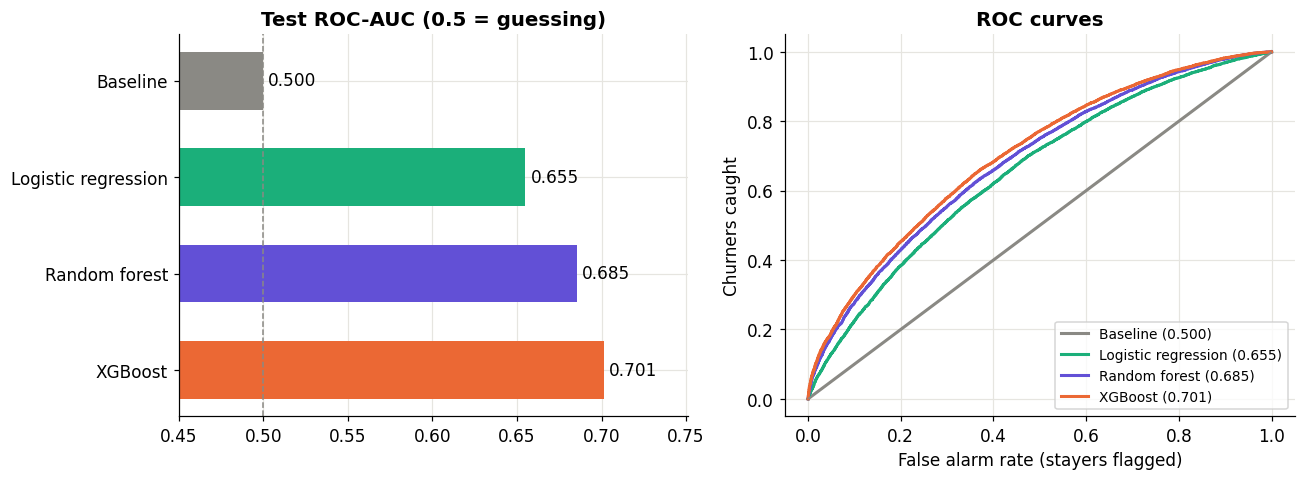

Best model: XGBoost


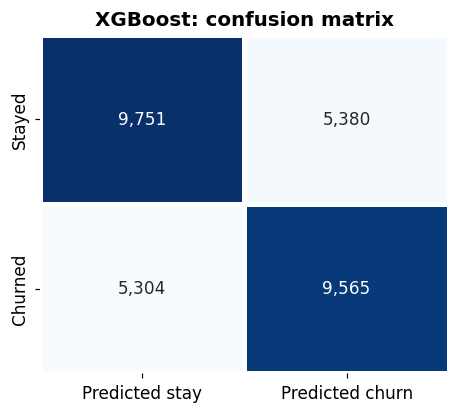

         mean   sum   lift  cum_capture
decile                                 
1       0.813  2439  1.640        0.164
2       0.678  2033  1.367        0.301
3       0.607  1821  1.225        0.423
4       0.565  1695  1.140        0.537
5       0.536  1607  1.081        0.645
6       0.464  1393  0.937        0.739
7       0.441  1323  0.890        0.828
8       0.368  1104  0.742        0.902
9       0.301   902  0.607        0.963
10      0.184   552  0.371        1.000


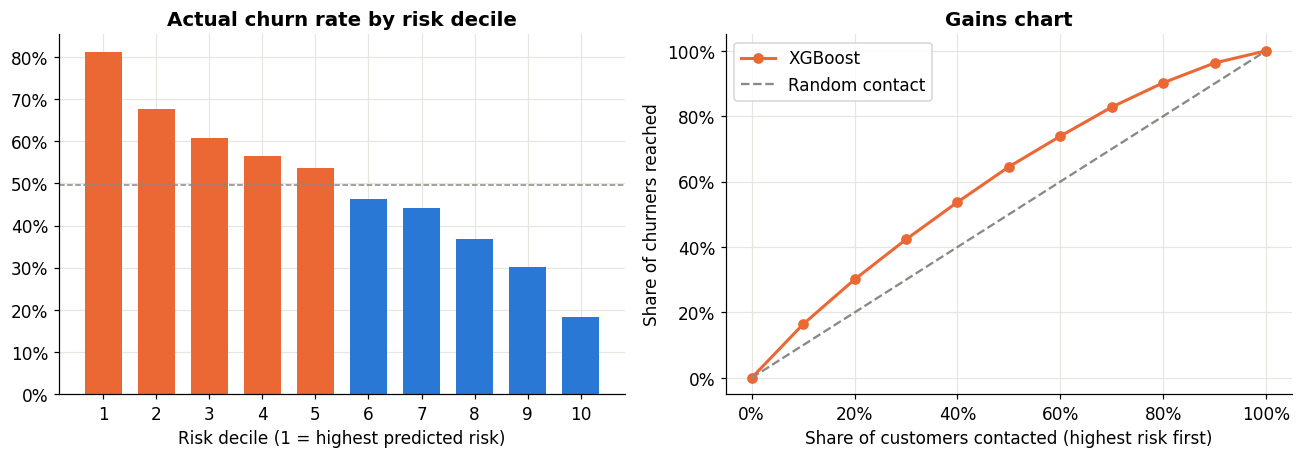

Top 10% lift: 1.64x | top 30% reach 42% of churners


In [ ]:
## 3. Features, models and evaluation
# feature engineering
def build_features(data):
    X = data.drop(columns=["churn", "Customer_ID"]).copy()
    X["eqpdays"] = X["eqpdays"].clip(lower=0)
    X["eqp_over_tenure"] = X["eqpdays"] / (X["months"] * 30.4 + 1)
    X["old_handset"] = (X["eqpdays"] > 365).astype(int)
    X["mou_trend_3v6"] = X["avg3mou"] / (X["avg6mou"] + 1)
    X["mou_trend_3vlife"] = X["avg3mou"] / (X["avgmou"] + 1)
    X["rev_trend_3vlife"] = X["avg3rev"] / (X["avgrev"] + 1)
    X["mou_change_pct"] = X["change_mou"] / (X["mou_Mean"] + 1)
    X["fail_rate"] = X["drop_blk_Mean"] / (X["attempt_Mean"] + 1)
    X["drop_rate"] = X["drop_vce_Mean"] / (X["plcd_vce_Mean"] + 1)
    X["any_custcare"] = (X["custcare_Mean"] > 0).astype(int)
    X["overage_share"] = X["ovrrev_Mean"] / (X["rev_Mean"].abs() + 1)
    X["rev_per_min"] = X["rev_Mean"] / (X["mou_Mean"] + 1)
    X["near_1yr"] = X["months"].between(10, 13).astype(int)
    for c in ["hnd_price", "income", "lor", "adults", "numbcars", "avg6mou"]:
        X[c + "_missing"] = X[c].isna().astype(int)
    return X.replace([np.inf, -np.inf], np.nan)

X = build_features(df)
y = df["churn"].astype(int)
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
print("Features:", X.shape[1], f"({len(num_cols)} numeric, {len(cat_cols)} categorical)")

# encodings
X_tree = X.copy()
for c in cat_cols:
    X_tree[c] = X_tree[c].astype("category").cat.codes
X_rf = X_tree.fillna(-999)
linear_prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=200))]), cat_cols),
])

# train/test split
idx_train, idx_test = train_test_split(X.index, test_size=0.3, random_state=42, stratify=y)
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
print("Train:", len(idx_train), "| Test:", len(idx_test))

# models
models = {
    "Baseline": (DummyClassifier(strategy="most_frequent"), "tree"),
    "Logistic regression": (Pipeline([("prep", linear_prep),
                                      ("lr", LogisticRegression(max_iter=2000, C=0.5))]), "linear"),
    "Random forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt",
                                             n_jobs=-1, random_state=42), "rf"),
    "XGBoost": (XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=6, subsample=0.8,
                              colsample_bytree=0.7, min_child_weight=5, eval_metric="logloss",
                              tree_method="hist", n_jobs=-1, random_state=42), "tree"),
}

def data_for(kind, idx):
    return {"linear": X, "tree": X_tree, "rf": X_rf}[kind].loc[idx]

# 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc = {}
for name, (m, kind) in models.items():
    s = cross_val_score(m, data_for(kind, idx_train), y_train, cv=cv, scoring="roc_auc")
    cv_auc[name] = s
    print(f"{name:20s} CV ROC-AUC = {s.mean():.4f} +/- {s.std():.4f}")

# test set results
rows, probas = [], {}
for name, (m, kind) in models.items():
    m.fit(data_for(kind, idx_train), y_train)
    p = m.predict_proba(data_for(kind, idx_test))[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p
    rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, p), "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0), "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred), "CV ROC-AUC": cv_auc[name].mean()})
results = pd.DataFrame(rows).set_index("Model").round(4)
print(results)

colors = {"Baseline": GREY, "Logistic regression": "#1baf7a", "Random forest": "#6250d6", "XGBoost": CHURN}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
names = results.index[::-1]
axes[0].barh(names, results.loc[names, "ROC-AUC"], color=[colors[n] for n in names], height=0.6)
axes[0].set_xlim(0.45, results["ROC-AUC"].max() + 0.05)
axes[0].axvline(0.5, color=GREY, ls="--", lw=1)
for i, n in enumerate(names):
    axes[0].text(results.loc[n, "ROC-AUC"] + 0.003, i, f"{results.loc[n, 'ROC-AUC']:.3f}", va="center")
axes[0].set_title("Test ROC-AUC (0.5 = guessing)", fontweight="bold")
for n in results.index:
    fpr, tpr, _ = roc_curve(y_test, probas[n])
    axes[1].plot(fpr, tpr, lw=2, color=colors[n], label=f"{n} ({results.loc[n, 'ROC-AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], ls="--", color=GREY, lw=1)
axes[1].set_xlabel("False alarm rate (stayers flagged)")
axes[1].set_ylabel("Churners caught")
axes[1].set_title("ROC curves", fontweight="bold")
axes[1].legend(fontsize=9, loc="lower right")
fig.tight_layout()
save(fig, "06_model_comparison")
plt.show()

best_name = results.drop("Baseline")["ROC-AUC"].idxmax()
p_test = probas[best_name]
print("Best model:", best_name)

cm = confusion_matrix(y_test, (p_test >= 0.5).astype(int))
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=["Predicted stay", "Predicted churn"], yticklabels=["Stayed", "Churned"], ax=ax)
ax.set_title(f"{best_name}: confusion matrix", fontweight="bold")
save(fig, "07_confusion_matrix")
plt.show()

# lift and gains
test = df.loc[idx_test, ["Customer_ID", "rev_Mean", "mou_Mean", "eqpdays", "change_mou", "custcare_Mean",
                         "drop_blk_Mean", "attempt_Mean", "ovrrev_Mean", "months", "churn"]].copy()
test["p_churn"] = p_test
test = test.sort_values("p_churn", ascending=False).reset_index(drop=True)
test["decile"] = pd.qcut(test.index, 10, labels=range(1, 11))
dec = test.groupby("decile", observed=False)["churn"].agg(["mean", "sum"])
dec["lift"] = dec["mean"] / test["churn"].mean()
dec["cum_capture"] = dec["sum"].cumsum() / test["churn"].sum()
print(dec.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].bar(dec.index.astype(str), dec["mean"] * 100,
            color=[CHURN if v > test["churn"].mean() else STAY for v in dec["mean"]], width=0.7)
axes[0].axhline(test["churn"].mean() * 100, ls="--", color=GREY, lw=1)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].set_xlabel("Risk decile (1 = highest predicted risk)")
axes[0].set_title("Actual churn rate by risk decile", fontweight="bold")
x = np.r_[0, np.arange(1, 11) * 10]
axes[1].plot(x, np.r_[0, dec["cum_capture"].values] * 100, marker="o", color=CHURN, lw=2, label=best_name)
axes[1].plot([0, 100], [0, 100], ls="--", color=GREY, label="Random contact")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_xlabel("Share of customers contacted (highest risk first)")
axes[1].set_ylabel("Share of churners reached")
axes[1].set_title("Gains chart", fontweight="bold")
axes[1].legend()
fig.tight_layout()
save(fig, "08_lift_gains")
plt.show()
print(f"Top 10% lift: {dec['lift'].iloc[0]:.2f}x | top 30% reach {dec['cum_capture'].iloc[2]:.0%} of churners")

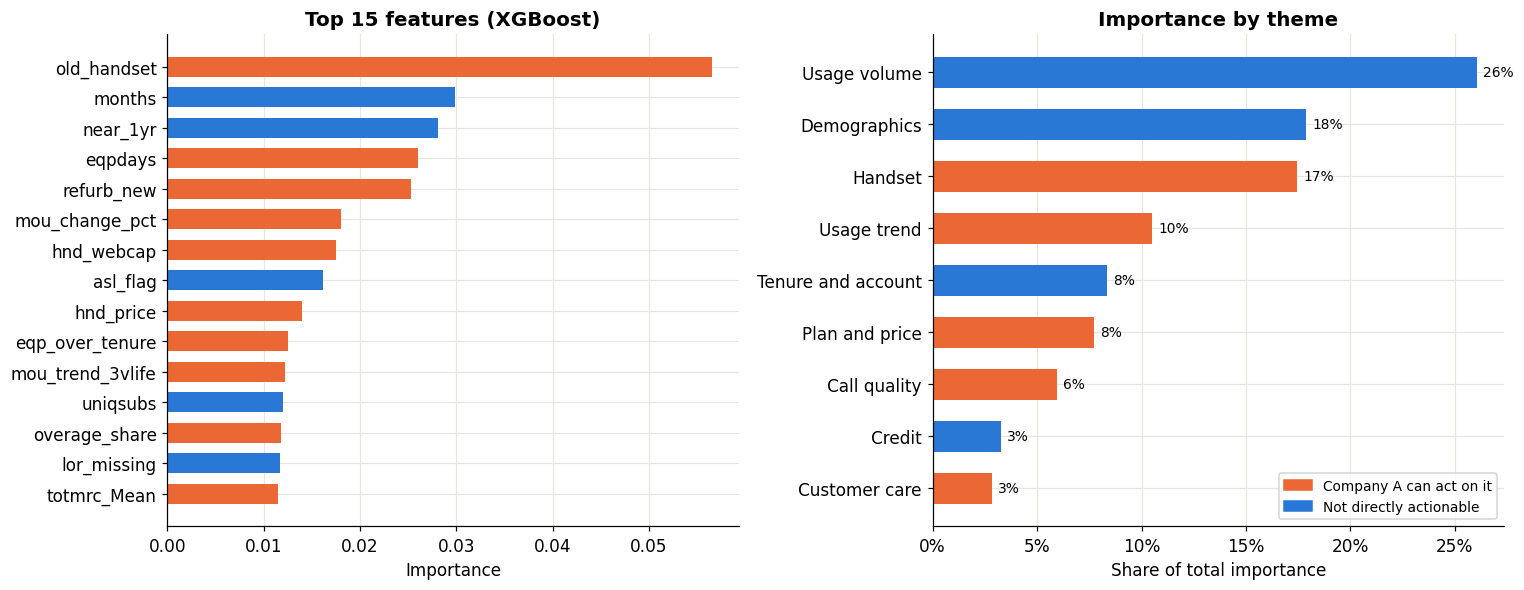

Importance from actionable themes: 44%
Usage volume          0.260
Demographics          0.179
Handset               0.174
Usage trend           0.105
Tenure and account    0.083
Plan and price        0.077
Call quality          0.060
Credit                0.033
Customer care         0.028
dtype: float32


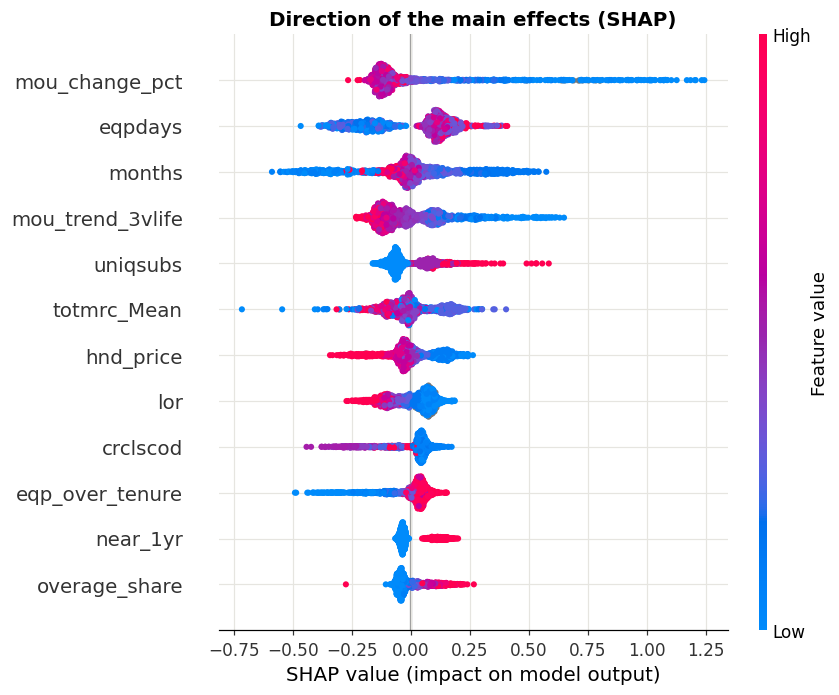

                   customers  churn_rate  avg_risk  avg_monthly_rev
lever                                                              
Handset upgrade        13692       0.544     0.550           49.984
Loyalty offer           4347       0.330     0.319           53.412
Plan right-sizing       5410       0.411     0.421           80.798
Renewal offer           6551       0.575     0.563           60.998

Offer mix in the top 30% risk group:
lever
Handset upgrade      0.551
Renewal offer        0.338
Plan right-sizing    0.092
Loyalty offer        0.018
Name: proportion, dtype: float64


In [ ]:
## 4. Churn drivers and retention offers
# feature importance
tree_model = models["XGBoost"][0]
imp = pd.Series(tree_model.feature_importances_, index=X_tree.columns).sort_values(ascending=False)

def theme(c):
    c = c.lower()
    if any(k in c for k in ["eqp", "hnd", "refurb", "phones", "models", "webcap", "dualband", "old_handset"]): return "Handset"
    if any(k in c for k in ["change", "trend", "avg3", "avg6"]): return "Usage trend"
    if any(k in c for k in ["drop", "blck", "fail", "unan"]): return "Call quality"
    if any(k in c for k in ["custcare", "cc_mou", "ccrnd"]): return "Customer care"
    if any(k in c for k in ["ovr", "totmrc", "rev_per", "overage", "da_", "roam"]): return "Plan and price"
    if any(k in c for k in ["months", "near_1yr", "uniqsubs", "actvsubs", "new_cell"]): return "Tenure and account"
    if any(k in c for k in ["crclscod", "asl_flag", "creditcd"]): return "Credit"
    if any(k in c for k in ["income", "lor", "adults", "kid", "marital", "ethnic", "ownrent", "dwll", "numbcars",
                            "truck", "rv", "forgntvl", "infobase", "hhstatin", "prizm", "area"]): return "Demographics"
    return "Usage volume"
actionable = {"Handset", "Usage trend", "Call quality", "Customer care", "Plan and price"}

themes = imp.groupby(imp.index.map(theme)).sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
top15 = imp.head(15)[::-1]
axes[0].barh(top15.index, top15.values, color=[CHURN if theme(c) in actionable else STAY for c in top15.index], height=0.65)
axes[0].set_title("Top 15 features (XGBoost)", fontweight="bold")
axes[0].set_xlabel("Importance")
axes[1].barh(themes.index, themes.values * 100, color=[CHURN if t in actionable else STAY for t in themes.index], height=0.6)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for i, v in enumerate(themes.values):
    axes[1].text(v * 100 + 0.3, i, f"{v:.0%}", va="center", fontsize=9)
axes[1].set_title("Importance by theme", fontweight="bold")
axes[1].set_xlabel("Share of total importance")
axes[1].legend(handles=[Patch(color=CHURN, label="Company A can act on it"),
                        Patch(color=STAY, label="Not directly actionable")], loc="lower right", fontsize=9)
fig.tight_layout()
save(fig, "09_feature_importance")
plt.show()
actionable_share = themes[themes.index.isin(actionable)].sum()
print(f"Importance from actionable themes: {actionable_share:.0%}")
print(themes.sort_values(ascending=False).round(3))

# SHAP
Xs = X_tree.loc[idx_test].sample(1500, random_state=42)
sv = shap.TreeExplainer(tree_model).shap_values(Xs)
shap.summary_plot(sv, Xs, max_display=12, show=False)
plt.title("Direction of the main effects (SHAP)")
save(plt.gcf(), "10_shap")
plt.show()

# one offer per customer, first matching rule
test["mou_change_pct"] = test["change_mou"] / (test["mou_Mean"] + 1)
overage_share = test["ovrrev_Mean"] / (test["rev_Mean"].abs() + 1)
conditions = [
    test["eqpdays"] > 365,                                         # handset older than a year
    test["months"].between(10, 15),                                # around the 1-year contract end
    (test["mou_change_pct"] < -0.25) | (overage_share > 0.15),     # usage drop or big overage
]
test["lever"] = np.select(conditions, ["Handset upgrade", "Renewal offer", "Plan right-sizing"],
                          default="Loyalty offer")

lev = test.groupby("lever").agg(customers=("churn", "size"), churn_rate=("churn", "mean"),
                                avg_risk=("p_churn", "mean"), avg_monthly_rev=("rev_Mean", "mean"))
print(lev.round(3))
print("\nOffer mix in the top 30% risk group:")
print(test.head(int(len(test) * 0.3))["lever"].value_counts(normalize=True).round(3))

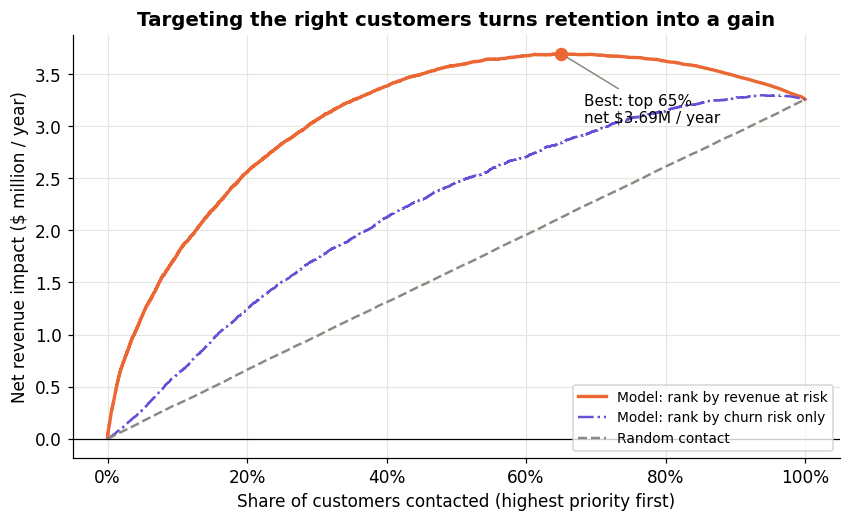

Contact top 10%: model $1,770,141 | random $331,136
Contact top 20%: model $2,561,159 | random $661,883
Contact top 30%: model $3,062,070 | random $985,550
Best contact share: 65% (65,080 customers)
Net impact, model:          $3,694,457
Net impact, random contact: $2,125,798
Net impact, contact all:    $3,258,760
                   customers  churners     cost  saved_revenue      net   ROI
lever                                                                        
Handset upgrade        30543     17793  1832600        3205660  1373060  0.75
Loyalty offer           5457      2327    81850         197815   115965  1.42
Plan right-sizing      12627      5803   315667        1362252  1046585  3.32
Renewal offer          16453     10080   493600        1652446  1158846  2.35


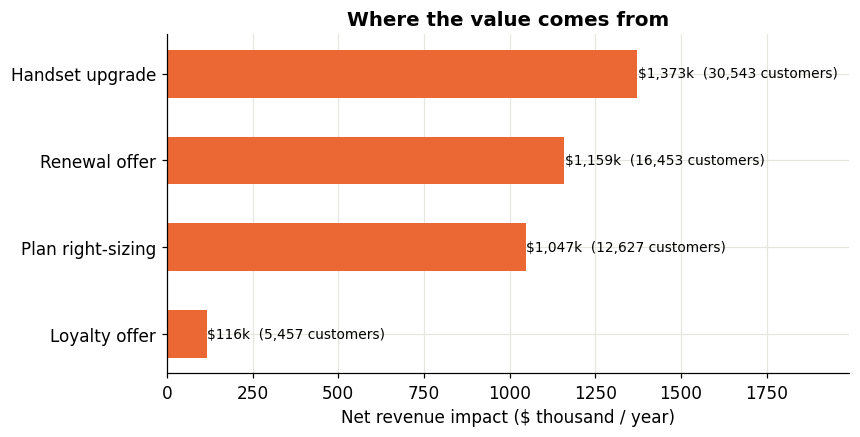

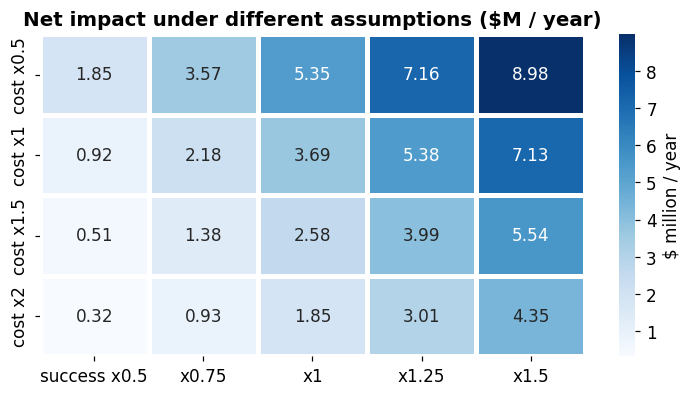

         real_churn_rate    value  break_even_cost
tier                                              
Top 1%              0.04  3256.39            21.55
1-5%                0.03  1768.29            10.47
5-10%               0.03  1239.12             6.63
10-20%              0.03   945.84             5.15
20-50%              0.02   645.12             3.00
50-100%             0.01   384.90             1.08


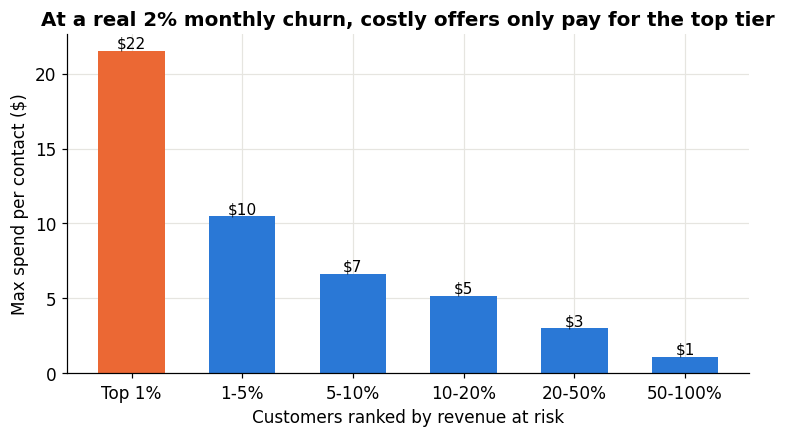

Customers: 100,000
Churn rate: 49.6%
Churner revenue per year: $34,449,546
Best model: XGBoost
Test ROC-AUC: 0.701
Accuracy: 0.644
Precision / Recall / F1: 0.640 / 0.643 / 0.642
CV ROC-AUC: 0.701 +/- 0.002
Top 10% lift: 1.64x
Top 30% churner capture: 42%
Actionable share of importance: 44%
Best contact share: 65%
Net impact, model: $3,694,457
Net impact, random contact: $2,125,798
Net impact, contact everyone: $3,258,760
Net impact, top 20% only: $2,561,159
Break-even cost, top 1% (real churn): $22


In [ ]:
## 5. Business impact)
# assumptions
horizon = 12
offers = {
    "Handset upgrade":   {"cost": 60, "success": 0.25},
    "Renewal offer":     {"cost": 30, "success": 0.20},
    "Plan right-sizing": {"cost": 25, "success": 0.20},
    "Loyalty offer":     {"cost": 15, "success": 0.10},
}
real_churn = 0.02

cost = test["lever"].map({k: v["cost"] for k, v in offers.items()})
succ = test["lever"].map({k: v["success"] for k, v in offers.items()})
test["value_if_saved"] = test["rev_Mean"].fillna(0).clip(lower=0) * horizon
test["gain"] = test["churn"] * succ * test["value_if_saved"] - cost
test["rev_at_risk"] = test["p_churn"] * test["rev_Mean"].fillna(0).clip(lower=0)

# profit curve
def curve(order_col=None, seed=None):
    t = test.sample(frac=1, random_state=seed) if order_col is None else test.sort_values(order_col, ascending=False)
    return t["gain"].cumsum().values

n = len(test)
depth = np.arange(1, n + 1) / n
c_model = curve("rev_at_risk")
c_prob = curve("p_churn")
c_random = np.mean([curve(seed=s) for s in range(20)], axis=0)
best_i = int(np.argmax(c_model))
scale = len(df) / n

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(depth * 100, c_model * scale / 1e6, color=CHURN, lw=2.2, label="Model: rank by revenue at risk")
ax.plot(depth * 100, c_prob * scale / 1e6, color="#6250d6", lw=1.6, ls="-.", label="Model: rank by churn risk only")
ax.plot(depth * 100, c_random * scale / 1e6, color=GREY, lw=1.6, ls="--", label="Random contact")
ax.axhline(0, color="black", lw=0.8)
ax.scatter([depth[best_i] * 100], [c_model[best_i] * scale / 1e6], color=CHURN, s=60, zorder=5)
ax.annotate(f"Best: top {depth[best_i]:.0%}\nnet ${c_model[best_i] * scale / 1e6:.2f}M / year",
            (depth[best_i] * 100, c_model[best_i] * scale / 1e6), xytext=(15, -45), textcoords="offset points",
            fontsize=10, arrowprops=dict(arrowstyle="-", color=GREY))
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Share of customers contacted (highest priority first)")
ax.set_ylabel("Net revenue impact ($ million / year)")
ax.set_title("Targeting the right customers turns retention into a gain", fontweight="bold")
ax.legend(loc="lower right", fontsize=9)
save(fig, "11_profit_curve")
plt.show()

for share in [0.1, 0.2, 0.3]:
    i = int(share * n) - 1
    print(f"Contact top {share:.0%}: model ${c_model[i] * scale:,.0f} | random ${c_random[i] * scale:,.0f}")
print(f"Best contact share: {depth[best_i]:.0%} ({int(depth[best_i] * len(df)):,} customers)")
print(f"Net impact, model:          ${c_model[best_i] * scale:,.0f}")
print(f"Net impact, random contact: ${c_random[best_i] * scale:,.0f}")
print(f"Net impact, contact all:    ${c_model[-1] * scale:,.0f}")

# breakdown by offer
camp = test.sort_values("rev_at_risk", ascending=False).head(best_i + 1).copy()
camp["cost"] = camp["lever"].map({k: v["cost"] for k, v in offers.items()})
camp["saved"] = camp["gain"] + camp["cost"]
by_offer = camp.groupby("lever").agg(customers=("churn", "size"), churners=("churn", "sum"),
                                     cost=("cost", "sum"), saved_revenue=("saved", "sum"), net=("gain", "sum"))
by_offer = (by_offer * scale).round(0).astype(int)
by_offer["ROI"] = (by_offer["net"] / by_offer["cost"]).round(2)
print(by_offer)

fig, ax = plt.subplots(figsize=(8, 4))
b = by_offer.sort_values("net")
ax.barh(b.index, b["net"] / 1e3, color=CHURN, height=0.55)
for i, (v, c) in enumerate(zip(b["net"], b["customers"])):
    ax.text(v / 1e3 + 2, i, f"${v/1e3:,.0f}k  ({c:,} customers)", va="center", fontsize=9)
ax.set_xlabel("Net revenue impact ($ thousand / year)")
ax.set_title("Where the value comes from", fontweight="bold")
ax.set_xlim(min(0, b["net"].min() / 1e3) * 1.1, b["net"].max() / 1e3 * 1.45)
save(fig, "12_value_by_offer")
plt.show()

# sensitivity
def best_net(s_mult, c_mult):
    g = test["churn"] * succ * s_mult * test["value_if_saved"] - cost * c_mult
    order = test["rev_at_risk"].sort_values(ascending=False).index
    return g.loc[order].cumsum().max() * scale

grid = pd.DataFrame([[best_net(s, c) / 1e6 for s in [0.5, 0.75, 1, 1.25, 1.5]] for c in [0.5, 1, 1.5, 2]],
                    index=["cost x0.5", "cost x1", "cost x1.5", "cost x2"],
                    columns=["success x0.5", "x0.75", "x1", "x1.25", "x1.5"])
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(grid, annot=True, fmt=".2f", cmap="Blues", linewidths=2, linecolor="white",
            cbar_kws={"label": "$ million / year"}, ax=ax)
ax.set_title("Net impact under different assumptions ($M / year)", fontweight="bold")
save(fig, "13_sensitivity")
plt.show()

# break-even offer cost at the real churn rate
p_s = test["churn"].mean()
w_stay = (1 - real_churn) / real_churn * p_s / (1 - p_s)
avg_success = np.mean([v["success"] for v in offers.values()])
tiers = test.sort_values("rev_at_risk", ascending=False).reset_index(drop=True)
tiers["tier"] = pd.cut(tiers.index / len(tiers), [0, 0.01, 0.05, 0.10, 0.20, 0.50, 1.0],
                       labels=["Top 1%", "1-5%", "5-10%", "10-20%", "20-50%", "50-100%"], include_lowest=True)
g = tiers.groupby("tier", observed=False).agg(churners=("churn", "sum"), n=("churn", "size"))
g["value"] = tiers[tiers["churn"] == 1].groupby("tier", observed=False)["value_if_saved"].mean()
g["real_churn_rate"] = g["churners"] / (g["churners"] + w_stay * (g["n"] - g["churners"]))
g["break_even_cost"] = g["real_churn_rate"] * avg_success * g["value"]
print(g[["real_churn_rate", "value", "break_even_cost"]].round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(g.index.astype(str), g["break_even_cost"], color=[CHURN] + [STAY] * (len(g) - 1), width=0.6)
for i, v in enumerate(g["break_even_cost"]):
    ax.text(i, v, f"${v:,.0f}", ha="center", va="bottom", fontsize=10)
ax.set_xlabel("Customers ranked by revenue at risk")
ax.set_ylabel("Max spend per contact ($)")
ax.set_title(f"At a real {real_churn:.0%} monthly churn, costly offers only pay for the top tier", fontweight="bold")
save(fig, "14_break_even")
plt.show()

# save tables and key numbers
with pd.ExcelWriter(out_dir / "tables.xlsx") as w:
    results.to_excel(w, sheet_name="model_results")
    dec.to_excel(w, sheet_name="lift_by_decile")
    rd.to_excel(w, sheet_name="revenue_deciles")
    pd.DataFrame(drivers).to_excel(w, sheet_name="churn_by_driver")
    themes.sort_values(ascending=False).to_frame("importance").to_excel(w, sheet_name="importance_themes")
    imp.head(30).to_frame("importance").to_excel(w, sheet_name="top_features")
    lev.to_excel(w, sheet_name="offers")
    by_offer.to_excel(w, sheet_name="campaign_by_offer")
    grid.to_excel(w, sheet_name="sensitivity")
    g.to_excel(w, sheet_name="break_even")

key = {
    "Customers": f"{n_customers:,}",
    "Churn rate": f"{churn_rate:.1%}",
    "Churner revenue per year": f"${rev_churners * 12:,.0f}",
    "Best model": best_name,
    "Test ROC-AUC": f"{results.loc[best_name, 'ROC-AUC']:.3f}",
    "Accuracy": f"{results.loc[best_name, 'Accuracy']:.3f}",
    "Precision / Recall / F1": f"{results.loc[best_name, 'Precision']:.3f} / {results.loc[best_name, 'Recall']:.3f} / {results.loc[best_name, 'F1']:.3f}",
    "CV ROC-AUC": f"{cv_auc[best_name].mean():.3f} +/- {cv_auc[best_name].std():.3f}",
    "Top 10% lift": f"{dec['lift'].iloc[0]:.2f}x",
    "Top 30% churner capture": f"{dec['cum_capture'].iloc[2]:.0%}",
    "Actionable share of importance": f"{actionable_share:.0%}",
    "Best contact share": f"{depth[best_i]:.0%}",
    "Net impact, model": f"${c_model[best_i] * scale:,.0f}",
    "Net impact, random contact": f"${c_random[best_i] * scale:,.0f}",
    "Net impact, contact everyone": f"${c_model[-1] * scale:,.0f}",
    "Net impact, top 20% only": f"${c_model[int(0.2 * n) - 1] * scale:,.0f}",
    "Break-even cost, top 1% (real churn)": f"${g['break_even_cost'].iloc[0]:,.0f}",
}
with open(out_dir / "key_numbers.txt", "w") as f:
    for k, v in key.items():
        f.write(f"{k}: {v}\n")
        print(f"{k}: {v}")